# Gate teleportation, level by level: Eq. (6.42) of L. Yeh's thesis

> **In short.**
> * **What this is.** L. Yeh's thesis (Proposition 6.41) proves that a CX between two logical qubits c and t of one code block can be done with transversal gates, by Gottesman's gate teleportation through a second block, the *ancilla*. The proof, Eq. (6.42), is a chain of five ZX-diagrams. Here the circuit of the first one is levelled up, one level per rewrite, and the levels give the five diagrams.
> * **Levels and rewrites.** Each level-up takes a part of the circuit (a block) and applies one rewrite to it (`level_up(..., rewrite=...)`); the level's picture is the whole circuit with that block rewritten (`reduced_level`). Three rewrites, each made of PyZX's single rules (`zxqec.gpf.rules`):
>   * `'thesis notation'`: PyZX's picture of a circuit in the thesis's notation (swaps as crossing wires, $|+\rangle$ as a green spider, a measurement as an effect followed by a new state);
>   * `'copy and fuse'`: the states $|0\rangle$ and $|+\rangle$ copied through spiders of the other colour (which removes the CX gates they control), spiders with one leg fused into their neighbour, identities on a straight piece of wire removed;
>   * `'remove identities'`: every identity spider removed, and neighbours whose phases cancel (`c[0]` and `c[0]`) fused.
> * **The levels.** 0: the circuit. 1 to 5: `'thesis notation'` on one stage each; level 5 is the first diagram of Eq. (6.42). 6: `'copy and fuse'` on the first teleportation (the second diagram). 7: `'remove identities'` on it (a picture between the second and the third). 8: `'copy and fuse'` up to the swap back (the third). 9: `'copy and fuse'` on everything (the fourth). 10: `'remove identities'` on everything (the fifth: a CX).
> * **The check.** Every level's picture is compared with the circuit, as linear maps, in every run (`equal_for_all_assignments`).
> * **How to read the pictures.** Lines are qubits, time runs left to right; green and red dots are Z- and X-spiders, a blue edge is a Hadamard. A red dot with one leg is $|0\rangle$ (at the end of a wire, a Z measurement with the result in its phase), a green one $|+\rangle$. A phase `c[0]` means $\pi$ times that result.
> * The same circuit on the toric code, and the tool's own reduction of it: [GateTeleportation.ipynb](GateTeleportation.ipynb).

In [1]:
%matplotlib inline
import sys
sys.path.insert(0, '..')
import pyzx as zx
from pyzx.circuit import Circuit
from pyzx.circuit.gates import CNOT, HAD, Measurement, Reset
from zxqec.qprogram import QProgram, ParityControlled
from zxqec.gpf import equal_for_all_assignments, reduce_gpf
from zxqec.spacetime import draw_program, view_levels

## The circuit of Eq. (6.42)

Four wires, each one logical qubit, drawn as in the thesis with the ancilla above the data block: 0 is the ancilla's c, 1 the ancilla's t, 2 the data block's c, 3 its t. The ancilla starts with c in $|+\rangle$ and t in $|0\rangle$; the data block's c and t are the inputs. Five stages:

0. teleport c into the ancilla: a CX from each ancilla wire to the same data wire; measure the data block's c (result `c[0]`) and prepare it again in $|0\rangle$ (`Reset`); if `c[0]` is 1, $X$ on the ancilla's c;
1. swap the ancilla's c and t;
2. the CX layer again: the ancilla's wire 1 now holds c, so this is a CX from c to t;
3. swap back;
4. teleport c back: the CX layer, then measure the ancilla's c in the X basis (result `c[1]`); if `c[1]` is 1, $Z$ on the data block's c.

deterministic: every run implements CNOT(0->1)


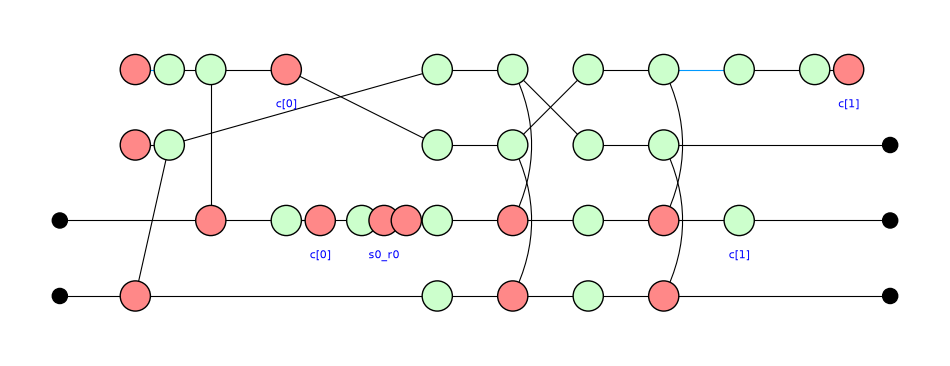

In [2]:
circuit = QProgram(4, bits=2, initial_states={0: '+', 1: '0'})
c = Circuit(4, bit_amount=2)
for gate in [CNOT(0, 2), CNOT(1, 3), Measurement(2, 0), Reset(2), ParityControlled('X', 0, ['c[0]'])]:
    c.add_gate(gate)
circuit.add_circuit(c, name='teleport c in')
circuit.add_permutation([(0, 1)], cycles=True, name='swap c and t')
c = Circuit(4, bit_amount=2)
for gate in [CNOT(0, 2), CNOT(1, 3)]:
    c.add_gate(gate)
circuit.add_circuit(c, name='CX layer', physical=True)
circuit.add_permutation([(0, 1)], cycles=True, name='swap back')
c = Circuit(4, bit_amount=2)
for gate in [CNOT(0, 2), CNOT(1, 3), HAD(0), Measurement(0, 1), ParityControlled('Z', 2, ['c[1]'])]:
    c.add_gate(gate)
circuit.add_circuit(c, name='teleport c back')
print(circuit.logical_action().verdict())
draw_program(circuit, show_time=False, labels=False, figsize=(12, 4.5))

## The levels

Each line below is one level-up: the blocks it groups and the rewrite it applies. `group_stages` makes one level per group, from the last stage to the first, so levels 1 to 5 each put one stage in the thesis's notation.

In [3]:
stages = ['teleport c in', 'swap c and t', 'CX layer', 'swap back', 'teleport c back']
notation = circuit.group_stages([(s, s, stages[s], None, 'thesis notation') for s in range(5)])
copied_in = circuit.level_up(notation, 0, 0, 'teleport c in', rewrite='copy and fuse')
wire_in = circuit.level_up(copied_in, 0, 0, 'teleport c in', rewrite='remove identities')
through_cx = circuit.level_up(wire_in, 0, 3, 'teleport c in, CX', rewrite='copy and fuse')
copied_back = circuit.level_up(through_cx, 0, 1, 'all', rewrite='copy and fuse')
done = circuit.level_up(copied_back, 0, 0, 'all', rewrite='remove identities')
for level in (notation, copied_in, wire_in, through_cx, copied_back, done):
    print(circuit.describe_level(level), end='\n\n')

Level 5 (5 blocks):
  Block 0 'teleport c in' <rewrite: thesis notation>: [teleport c in]
  Block 1 'swap c and t' <rewrite: thesis notation>: [swap c and t]
  Block 2 'CX layer' <rewrite: thesis notation>: [CX layer]
  Block 3 'swap back' <rewrite: thesis notation>: [swap back]
  Block 4 'teleport c back' <rewrite: thesis notation>: [teleport c back]

Level 6 (5 blocks):
  Block 0 'teleport c in' <rewrite: copy and fuse>: [teleport c in]
  Block 1 'swap c and t' <rewrite: thesis notation>: [swap c and t]
  Block 2 'CX layer' <rewrite: thesis notation>: [CX layer]
  Block 3 'swap back' <rewrite: thesis notation>: [swap back]
  Block 4 'teleport c back' <rewrite: thesis notation>: [teleport c back]

Level 7 (5 blocks):
  Block 0 'teleport c in' <rewrite: remove identities>: [teleport c in]
  Block 1 'swap c and t' <rewrite: thesis notation>: [swap c and t]
  Block 2 'CX layer' <rewrite: thesis notation>: [CX layer]
  Block 3 'swap back' <rewrite: thesis notation>: [swap back]
  Block 4 

## Level 0: the circuit as PyZX writes it

PyZX writes some parts differently from the thesis: $|+\rangle$ is $|0\rangle$ followed by a Hadamard edge; the measurement of the data block's c is a Z-spider that copies c onto an X-spider with the result `c[0]`, and the wire goes on; the new preparation of c (`Reset`) is a Z-spider with an X-spider whose phase `s0_r0` is the result of the old state, thrown away, then a new $|0\rangle$; the X measurement is a Hadamard edge, then a measurement; the swaps are spiders with no phase on the new wires.

The circuit has one constraint: the thrown-away result `s0_r0` always equals `c[0]`, as the Z-spider copies the same value onto both. The runs of the circuit are those where `s0_r0 + c[0]` is 0; every check below is made in those runs.

constraints: ['s0_r0 + c[0]']


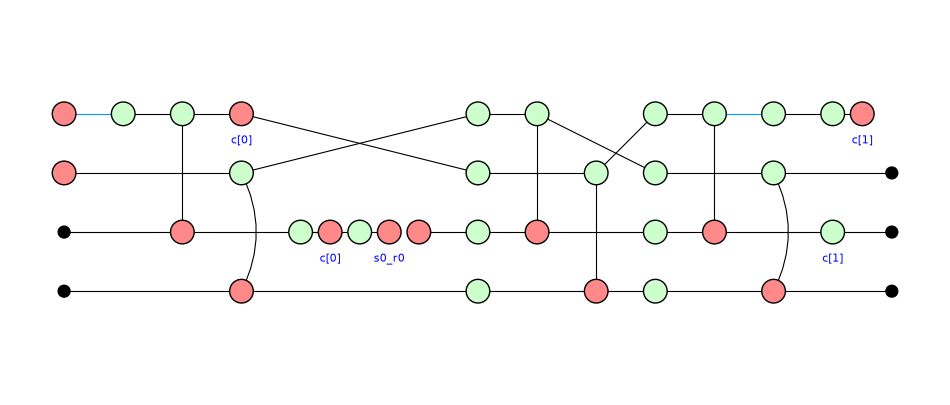

In [4]:
circuit_graph = circuit.quantum_graph()
runs = reduce_gpf(circuit_graph).constraints
print("constraints:", [str(x) for x in runs])
zx.draw_matplotlib(circuit_graph, figsize=(12, 5))

## Level 5: the thesis's notation (the first diagram)

Each stage rewritten by `'thesis notation'`: the swaps' spiders are removed, so the swaps are crossing wires; the $|0\rangle$ with a Hadamard edge becomes a green $|+\rangle$; the result `c[0]` is copied through the Z-spider that measured c, which leaves the measurement effect `c[0]` after the CX's target and, on the reset's thrown-away X-spider, a closed piece that becomes the number $1 + e^{i\pi(\texttt{s0\_r0} + \texttt{c[0]})}$ (2 in every run); the X measurement becomes the green effect `c[1]`. The picture is the first diagram of Eq. (6.42).

Level 5 (5 blocks), rewritten:
  Block 0: teleport c in (1 children): 13 spiders -> 9 after rewrite thesis notation
  Block 1: swap c and t (1 children): 4 spiders -> 0 after rewrite thesis notation
  Block 2: CX layer (1 children): 4 spiders -> 4 after rewrite thesis notation
  Block 3: swap back (1 children): 4 spiders -> 0 after rewrite thesis notation
  Block 4: teleport c back (1 children): 8 spiders -> 6 after rewrite thesis notation
the same map as the circuit in every run: True


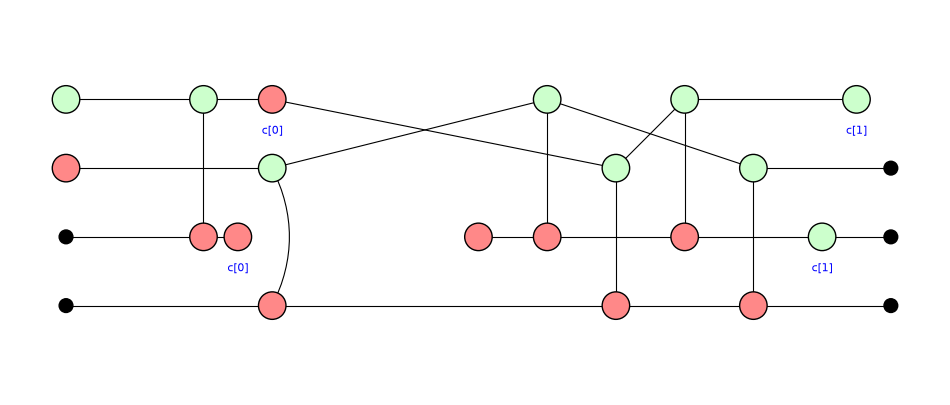

In [5]:
print(circuit.describe_reduced(notation))
level = circuit.reduced_level(notation)
print("the same map as the circuit in every run:", equal_for_all_assignments(circuit_graph, level.graph, constraints=runs))
zx.draw_matplotlib(level.graph, figsize=(12, 5))

## Level 6: teleporting c into the ancilla (the second diagram)

`'copy and fuse'` on the first stage. The $|0\rangle$ of the ancilla's t is copied through its CX's control: one copy fuses with the target on the data block's t, which leaves an identity on a straight wire, removed; the other goes on along the ancilla's wire. The $|+\rangle$ fuses with its CX's control and the target on the data block's c with the effect `c[0]`. Wire c now runs from the data block's input up into the ancilla; the spider where it turns stays, as in the thesis.

teleport c in (1 children): 9 spiders -> 5 after rewrite copy and fuse
the same map as the circuit in every run: True


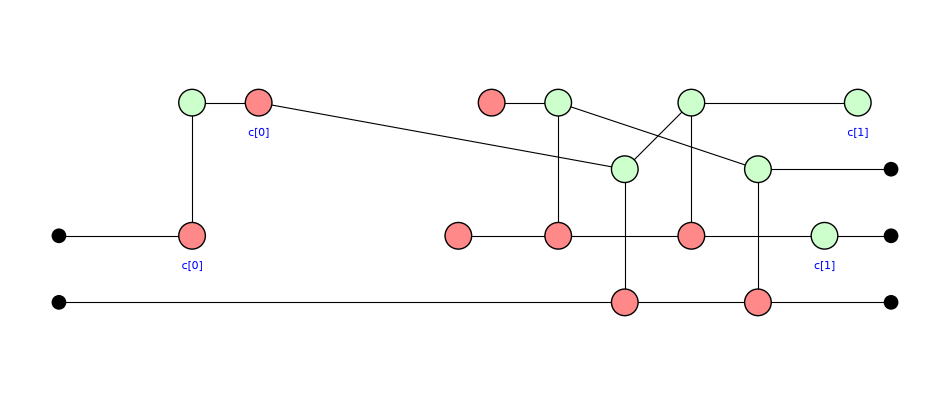

In [6]:
print(circuit.reduced_block(copied_in, 0))
level = circuit.reduced_level(copied_in)
print("the same map as the circuit in every run:", equal_for_all_assignments(circuit_graph, level.graph, constraints=runs))
zx.draw_matplotlib(level.graph, figsize=(12, 5))

## Level 7: the teleportation is a wire

`'remove identities'` on the first stage. The spider where wire c turns is an identity; removed, the effect `c[0]` and the correction `c[0]` meet, their phases cancel, and the identity left is removed: wire c goes straight from the data block's input into the ancilla. The thesis does this inside its second "=", together with the next level.

teleport c in (1 children): 5 spiders -> 2 after rewrite remove identities
the same map as the circuit in every run: True


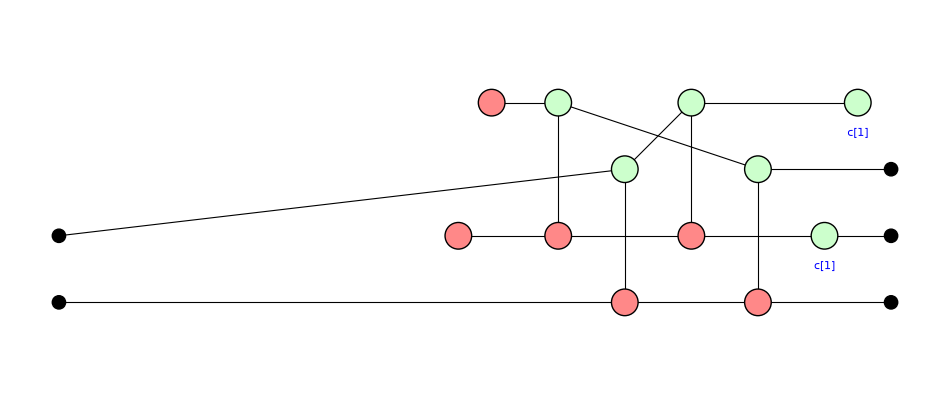

In [7]:
print(circuit.reduced_block(wire_in, 0))
level = circuit.reduced_level(wire_in)
print("the same map as the circuit in every run:", equal_for_all_assignments(circuit_graph, level.graph, constraints=runs))
zx.draw_matplotlib(level.graph, figsize=(12, 5))

## Level 8: the CX from c to t (the third diagram)

`'copy and fuse'` on stages 0 to 3, glued from the block of level 7 and the swaps and the CX layer of level 5. The $|0\rangle$ that came out of the first stage is copied through the second layer's CX on wire 0: one copy fuses with the target on the data block's c, which then fuses with the new $|0\rangle$ there; the other goes on. One CX of the layer is left: from wire c, on the ancilla's wire 1 after the swap, to t.

teleport c in, CX (4 children): 6 spiders -> 4 after rewrite copy and fuse
the same map as the circuit in every run: True


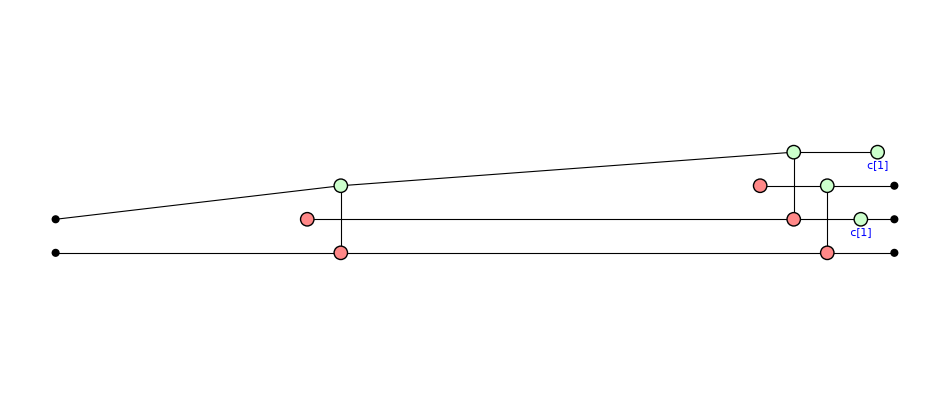

In [8]:
print(circuit.reduced_block(through_cx, 0))
level = circuit.reduced_level(through_cx)
print("the same map as the circuit in every run:", equal_for_all_assignments(circuit_graph, level.graph, constraints=runs))
zx.draw_matplotlib(level.graph, figsize=(12, 5))

## Level 9: teleporting c back (the fourth diagram)

`'copy and fuse'` on the whole circuit. The $|0\rangle$ on the ancilla's wire 1 is copied through the third layer's CX: one copy fuses with the target on t (an identity on a straight wire, removed), the other is the output of the ancilla's t, $|0\rangle$. The $|0\rangle$ on the data block's c fuses with its CX's target, which is now an identity where wire c turns and stays; the CX's control on wire c fuses with the effect `c[1]`.

all (2 children): 10 spiders -> 6 after rewrite copy and fuse
the same map as the circuit in every run: True


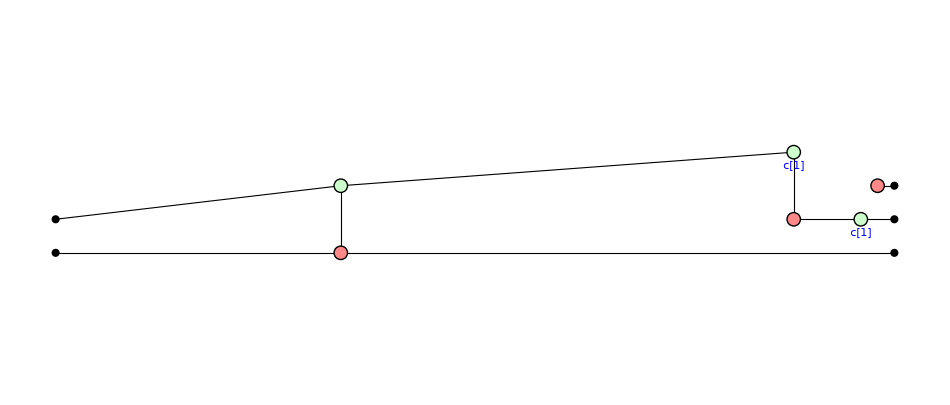

In [9]:
print(circuit.reduced_block(copied_back, 0))
level = circuit.reduced_level(copied_back)
print("the same map as the circuit in every run:", equal_for_all_assignments(circuit_graph, level.graph, constraints=runs))
zx.draw_matplotlib(level.graph, figsize=(12, 5))

## Level 10: the CX (the fifth diagram)

`'remove identities'` on the whole circuit. The identity where wire c turns is removed; the spider with `c[1]` and the correction `c[1]` meet, cancel, and the identity left is removed. What is left is a CX from c to t, the ancilla's t in $|0\rangle$, and the number from the reset in the scalar.

all (1 children): 6 spiders -> 3 after rewrite remove identities
the same map as the circuit in every run: True
scalar: sqrt(2)^-4(1+exp((c[0] + s0_r0)ipi))


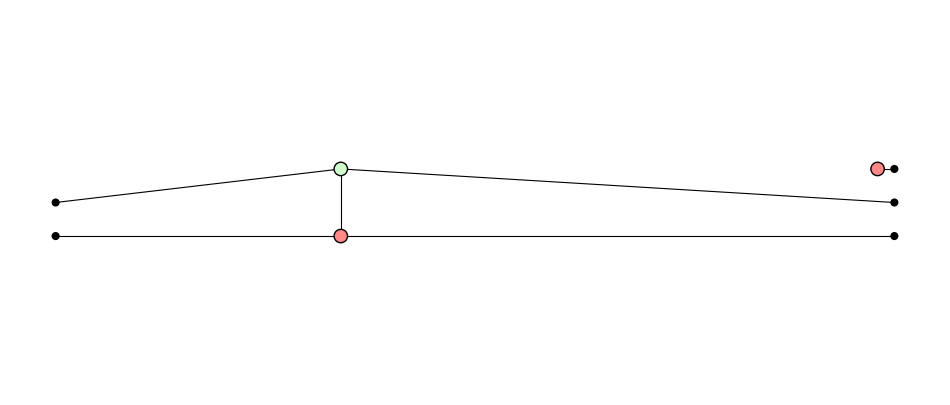

In [10]:
print(circuit.reduced_block(done, 0))
level = circuit.reduced_level(done)
print("the same map as the circuit in every run:", equal_for_all_assignments(circuit_graph, level.graph, constraints=runs))
print("scalar:", level.graph.scalar)
zx.draw_matplotlib(level.graph, figsize=(12, 5))

## The levels window

`view_levels` shows a level of the program: the blocks of that level outlined in the circuit (the blocks they were made from dashed), the whole circuit as the level rewrites it, and the selected block after its rewrite. With an interactive backend the slider moves through the levels; here it is level 8.

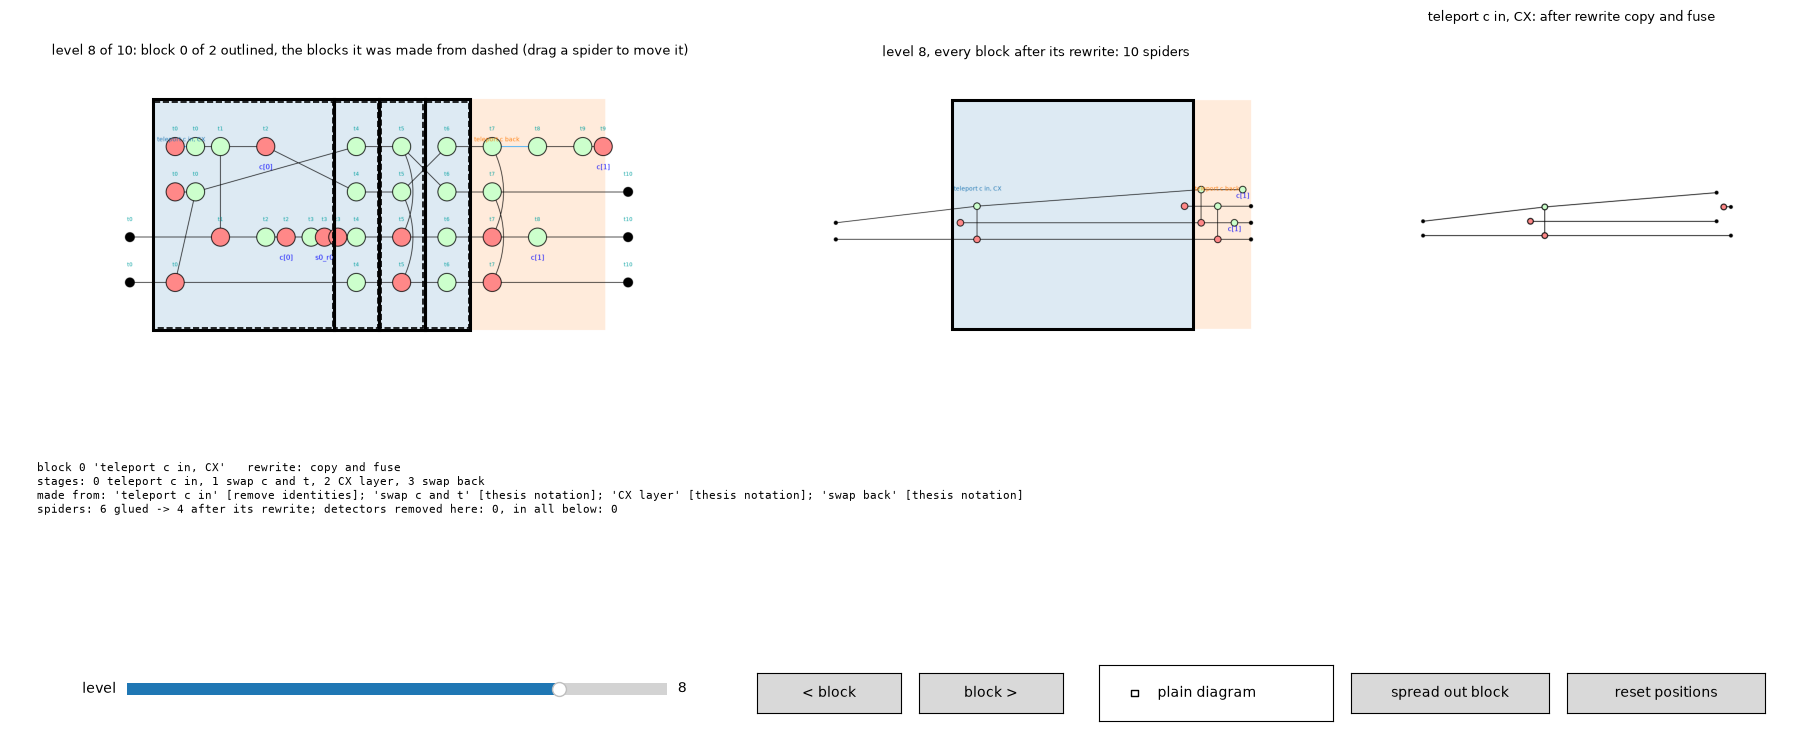

In [11]:
window = view_levels(circuit, through_cx, 0)

## How this differs from the figure

* Each block has two logical qubits, c and t; the figure has more (the dots). In the ancilla, every other wire starts in $|0\rangle$ and loses its CXs to the copy rule as t does; in the data block, the other wires lose their CX targets and pass through.
* Level 7 is not in the figure: the thesis removes the turn of wire c and cancels the two `c[0]` in the same "=" as the CX layer.
* The thesis keeps the ancilla's c after its X measurement, in the state $Z^{b}|+\rangle$ (the second $b\pi$ at its end); in the program the measured qubit is not an output.
* The thesis ends the data block's c at its measurement and starts a new wire in $|0\rangle$. The program's `Reset` carries the extra result `s0_r0`; the thesis's notation removes it and leaves the number $1 + e^{i\pi(\texttt{s0\_r0} + \texttt{c[0]})}$, 2 in every run, in the scalar.
* The pictures are PyZX's drawings, with each spider where the circuit, or the copy rule, put it; a copied $|0\rangle$ can sit on top of another wire. The thesis draws wire c straight in the last picture.

What is not covered: the blocks and the order of the rewrites are chosen to follow the figure; the tool checks each level against the circuit, but it does not choose them. The tool's own reduction of the same circuit, which needs no choices, is Part 1 of [GateTeleportation.ipynb](GateTeleportation.ipynb).